#EXPLORATORY DATA ANALYSIS

,minutes_watched,CLV,region_0,region_1,region_2,channel_1,channel_2,channel_3,channel_4,channel_5,channel_6,channel_7,channel_8
minutes_watched,1.000000,0.114153,-0.037041,-0.004707,0.038583,-0.006665,0.034347,0.007681,-0.020212,-0.015796,-0.024114,0.004660,0.015535
CLV,0.114153,1.000000,0.192527,0.208601,-0.320448,0.018108,-0.042313,0.095619,-0.070633,-0.044381,-0.012982,-0.025334,0.019438
region_0,-0.037041,0.192527,1.000000,-0.275039,-0.779753,0.032869,-0.042251,0.079869,-0.061812,-0.047585,-0.026750,-0.077989,0.093788
region_1,-0.004707,0.208601,-0.275039,1.000000,-0.387478,0.000673,-0.017144,-0.008067,-0.017431,-0.026109,0.061514,-0.008435,0.016341
region_2,0.038583,-0.320448,-0.779753,-0.387478,1.000000,-0.031955,0.051676,-0.071330,0.070621,0.062629,-0.014409,0.080273,-0.100570
channel_1,-0.006665,0.018108,0.032869,0.000673,-0.031955,1.000000,-0.135646,-0.291035,-0.208105,-0.057083,-0.131508,-0.173826,-0.131262
channel_2,0.034347,-0.042313,-0.042251,-0.017144,0.051676,-0.135646,1.000000,-0.186093,-0.133066,-0.036500,-0.084089,-0.111147,-0.083931
channel_3,0.007681,0.095619,0.079869,-0.008067,-0.071330,-0.291035,-0.186093,1.000000,-0.285498,-0.078313,-0.180416,-0.238471,-0.180078
channel_4,-0.020212,-0.070633,-0.061812,-0.017431,0.070621,-0.208105,-0.133066,-0.285498,1.000000,-0.055997,-0.129006,-0.170519,-0.128765
channel_5,-0.015796,-0.044381,-0.047585,-0.026109,0.062629,-0.057083,-0.036500,-0.078313,-0.055997,1.000000,-0.035387,-0.046774,-0.035320


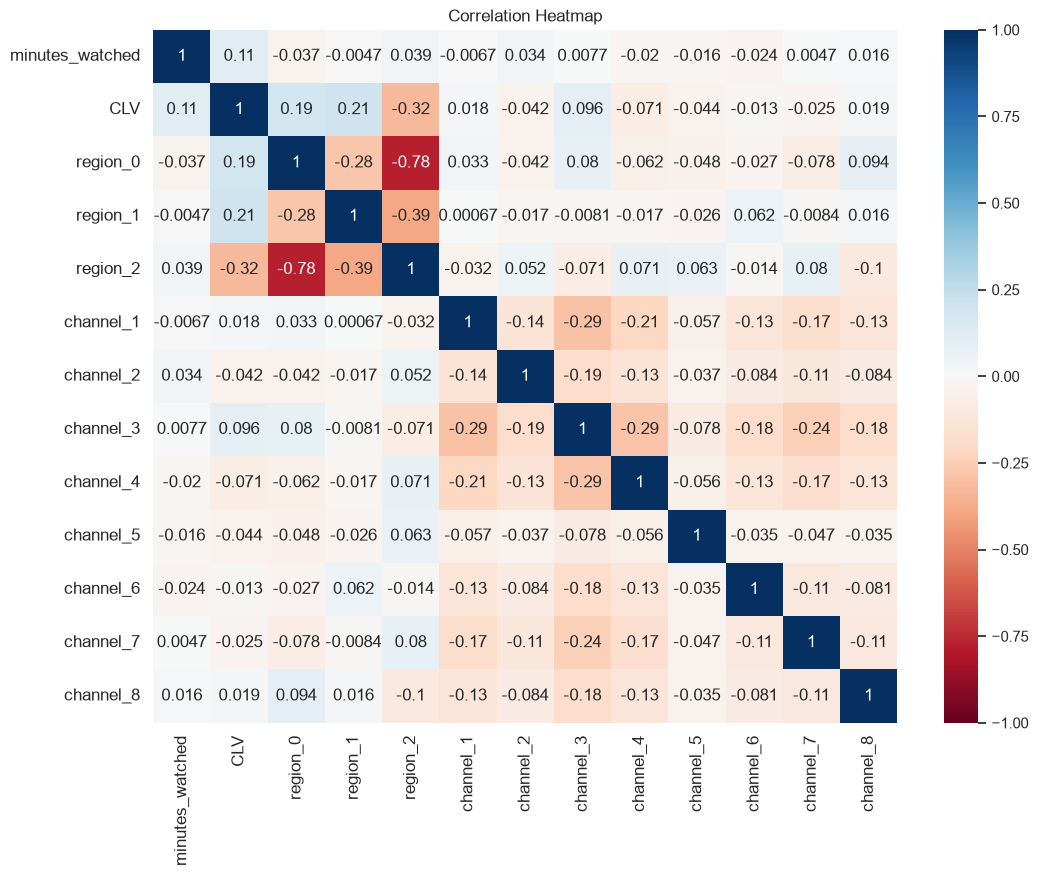

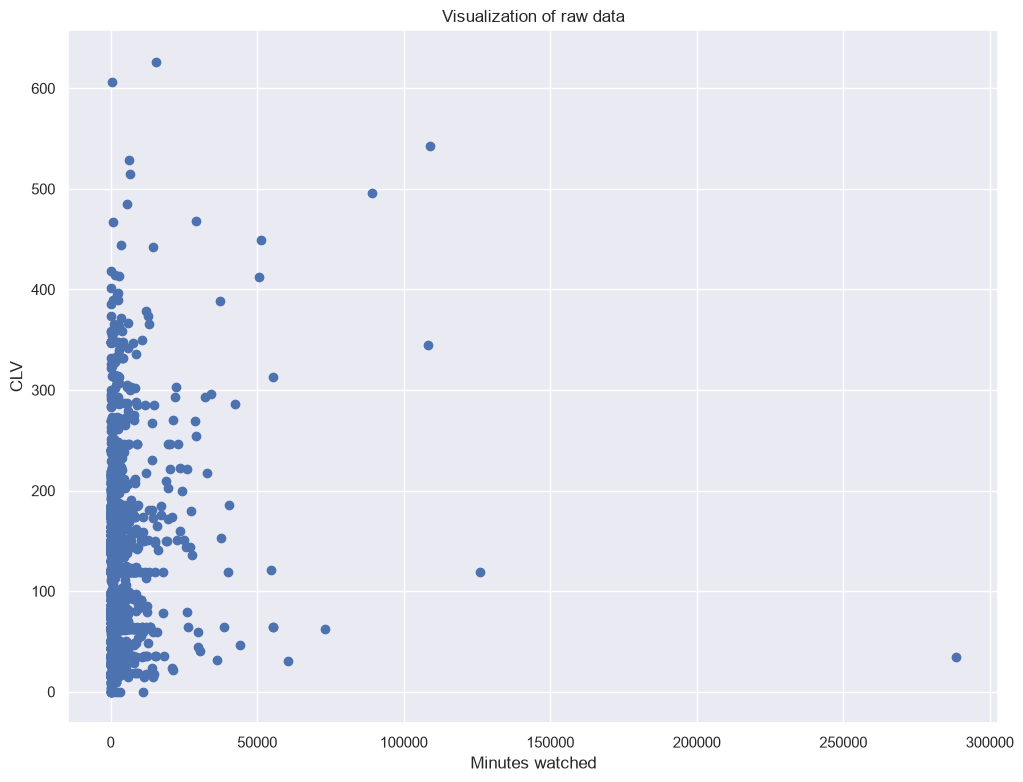

In [12]:
import numpy as np
import pandas as pd
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.preprocessing import StandardScaler

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans

from sklearn.decomposition import PCA

## Load the data
df = pd.read_csv('customer_segmentation_data.csv')
df.describe()
#segmentation 
df_segmentation = df.fillna(0)

# Feature engineering: Create dummies for region and channel
segment_dummies_2 = pd.get_dummies(df_segmentation['region'], prefix='region', prefix_sep='_')
df_segmentation = pd.concat([df_segmentation, segment_dummies_2], axis=1)

segment_dummies = pd.get_dummies(df_segmentation['channel'], prefix='channel', prefix_sep='_')
df_segmentation = pd.concat([df_segmentation, segment_dummies], axis=1)

# Drop the original categorical columns
df_segmentation = df_segmentation.drop(['region', 'channel'], axis=1)

# --- 3. Correlation Estimate & Heatmap ---
display(df_segmentation.corr())

plt.figure(figsize = (12, 9))
s = sns.heatmap(df_segmentation.corr(),
               annot = True, 
               cmap = 'RdBu',
               vmin = -1, 
               vmax = 1)
s.set_yticklabels(s.get_yticklabels(), rotation = 0, fontsize = 12)
s.set_xticklabels(s.get_xticklabels(), rotation = 90, fontsize = 12)
plt.title('Correlation Heatmap')
plt.savefig('corr.png')
plt.show()

# --- 4. Visualize Raw Data ---
plt.figure(figsize = (12, 9))
plt.scatter(df_segmentation.iloc[:, 0], df_segmentation.iloc[:, 1])
plt.xlabel('Minutes watched')
plt.ylabel('CLV')
plt.title('Visualization of raw data')
plt.savefig("scatter.png")
plt.show()

# Model Implementation (Standardization & K-Means Clustering)

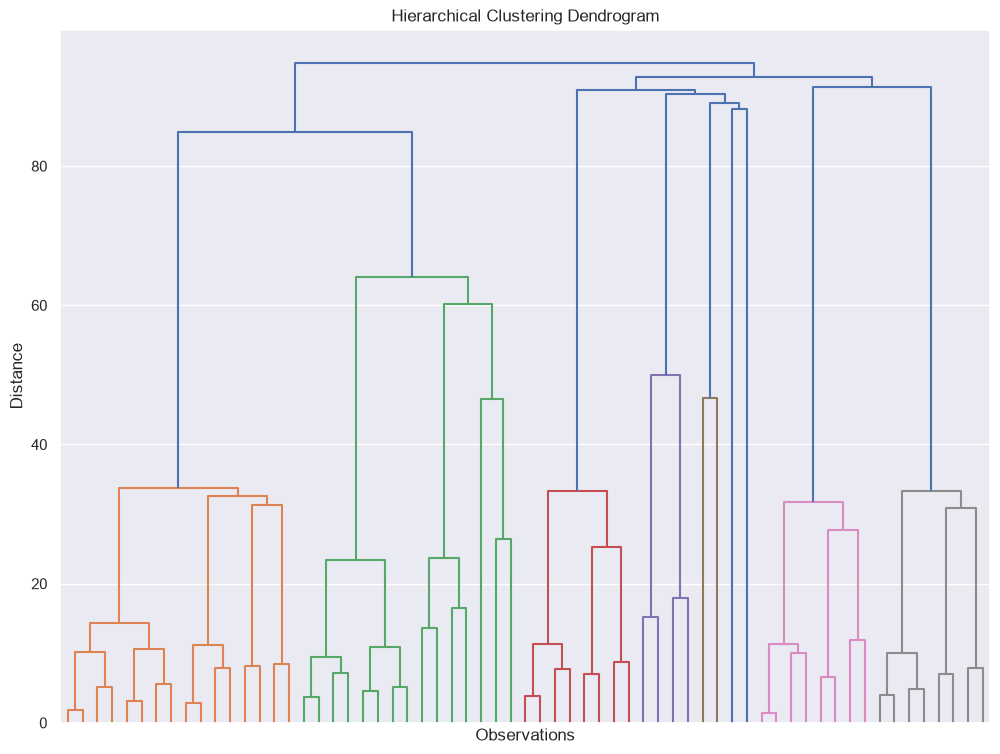

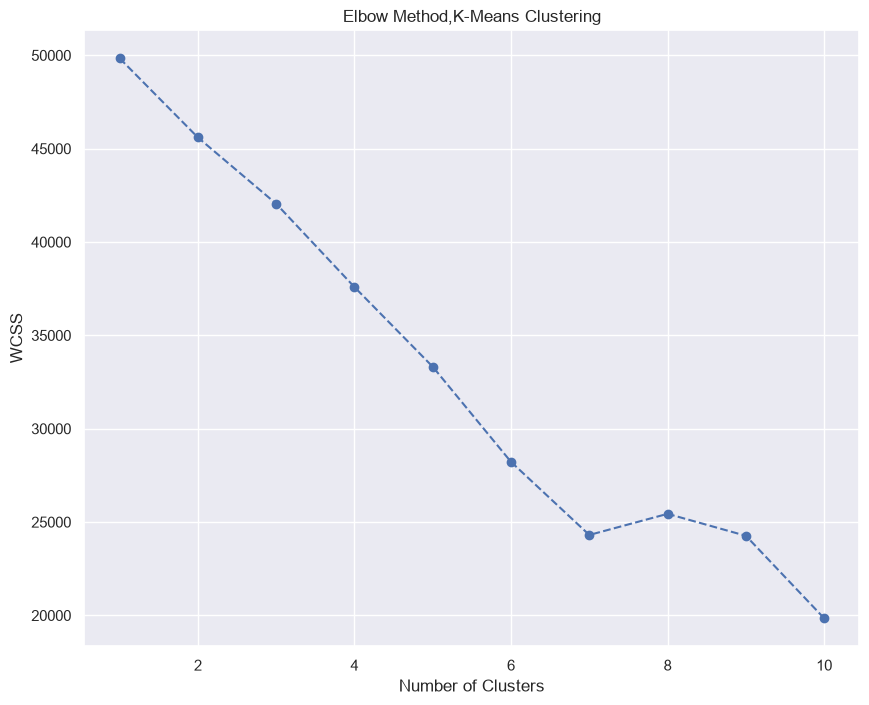

In [20]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Standardize the features in df_segmentation
segmentation_std = scaler.fit_transform(df_segmentation)

# Perform hierarchical clustering using Ward's method
hier_clust = linkage(segmentation_std, method = 'ward')

# Plot the dendrogram
plt.figure(figsize = (12, 9))
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Observations')
plt.ylabel('Distance')
dendrogram(hier_clust,
           truncate_mode = 'level',
           p = 5,
           show_leaf_counts = False,
           no_labels=True)
plt.savefig('dendrogram.png')
plt.show()
#kmeans clustering
# Determine the optimal number of clusters using the elbow method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(segmentation_std)
    wcss.append(kmeans.inertia_)
#plot the elbow method graph
plt.figure(figsize=(10, 8))
plt.plot(range(1, 11), wcss, marker='o',linestyle='--')
plt.title('Elbow Method,K-Means Clustering')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

#MODEL EVALUATION AND RESULTS

Based on that information, we can formulate the following clusters.
Segment 0 – Instagram Explorers (289 Observations): These customers are from all regions, with a slightly larger group from the rest of the world. They discovered the platform through Instagram and have a relatively moderate level of engagement and expenditure.

Segment 1 – LinkedIn Networkers (391 Observations): This segment consists entirely of customers from the rest of the world who have heard about your platform via LinkedIn. They have a high level of engagement but slightly lower spending.

Segment 2 – Friends' Influence (424 Observations): This group primarily comprises customers from the rest of the world who discovered the platform through friends. They have high engagement and moderate spending.

Segment 3 – Google-YouTube Mix (939 Observations): These customers from the rest of the world discovered the platform via a mix of Google and YouTube. They have very high engagement and moderate spending.

Segment 4 – Anglo-Saxon Multi-Channel (1055 Observations): This segment includes customers from the US, Canada, The UK, and Australia who discovered the platform through a mix of Google, YouTube, and LinkedIn. They have high engagement and higher-than-average spending.

Segment 5 – European Multi-Channel (372 Observations): These customers are from Western Europe and heard about the platform from various sources, including Google, YouTube, LinkedIn, and friends. They have high engagement and the highest spending level.

Segment 6 – Twitter Devotees (58 Observations): This small group of customers discovered the platform via Twitter. They’re from all regions, with a majority from the rest of the world. They have the lowest engagement but moderate spending.

Segment 7 – Facebook Followers (306 Observations): This group mainly heard about the platform from Facebook. They are from all regions but predominantly from the rest of the world. They have the highest level of engagement and moderate spending.

#DATA INTERPRETATION


Segments: 
First, we’ll focus on the smallest segment, Twitter Devotees, with only 58 observations. Based on the characteristics of the cluster, we conclude that our efforts on Twitter bear little fruit. Our suggestion would be to reduce spending there to a minimum. And invest little resources to upload content to the platform because the results are unsatisfactory—perhaps due to the turmoil of the platform in recent months. We suggest marketing become an early adopter of a new competitor platform, such as Threads.

Facebook. 
Although they’re not the most significant segment—close to 8% of all customers, with average spending in the lower half compared to the rest—the Facebook group is the most dedicated to learning. Their average watch time is over an impressive 2,700 minutes.
In terms of countries, it’s a mixed bag, with a little under a third from the US, Canada, or United Kingdom and over 60% from the rest of the world. It would be worth exploring how these students interact with the platform and why their group is more motivated to study. But this would be the focus of a different analysis on engagement.

Performance by region: 
Overall, the Anglo-Saxon channel has the best performance. Customers from the USA, Canada, The UK, and Australia make up the largest customer segment from that region.  And the Google-YouTube Mix has the second largest segment, with over 900 customers from that region. The second largest area is the rest of the world.
The fewest customers are from Western Europe. Considering our initial hypothesis of exact spending for all three regions, we conclude that Western Europe’s marketing efforts are insufficient. At the same time, we observe that this segment has the highest CLV, so addressing this region and improving performance is crucial.

CLV: 
Let's also address the spending in various regions of the countries because this is crucial to marketing. The two highest-paying clusters are the Anglo-Saxon Multichannel and the European Multichannel. The European countries top the list of spending. When we look at the channels—through which these two segments come to the platform—we see a mix between Google, YouTube, and LinkedIn.

Conclusion
Based on that information, we advise marketing to focus on these acquisition channels for these regions and increase spending. This would be worthwhile because the CLV of these customers is the highest across our customer segments—meaning they are worth pursuing.

And what about the remaining regions and their channel of acquisition?

For the rest of the world, LinkedIn is the most successful channel in terms of conversion, followed by Facebook, which is why it should be the primary source for attracting customers from these regions. LinkedIn is a platform that provides excellent organic reach. Our content there is very popular; many students share their certificates and spread the word organically.